In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers import (
    Seq2SeqTrainer, Seq2SeqTrainingArguments,
    pipeline, DataCollatorForSeq2Seq, EarlyStoppingCallback
)
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
from safetensors.torch import load_file

In [2]:
# Read the CSV file
data = pd.read_csv("/kaggle/input/datasets/belovedorange/first-nagamese-english-parallel-corpus-fnpc-25/bible.csv")
extra_data=pd.read_csv("/kaggle/input/datasets/belovedorange/first-nagamese-english-parallel-corpus-fnpc-25/Nagamese Khobor Comic and Other Resouces.csv")

In [3]:
print("Bible dataset:", len(data))
print("Non-Bible dataset:", len(extra_data))

Bible dataset: 7950
Non-Bible dataset: 821


In [4]:
# Load model and tokenizer
tokenizer = AutoTokenizer.from_pretrained("facebook/nllb-200-distilled-600M")
model = AutoModelForSeq2SeqLM.from_pretrained("facebook/nllb-200-distilled-600M")

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.3M [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/2.46G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/2.46G [00:00<?, ?B/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

In [5]:
data["source"] = "Bible"
extra_data["source"] = "Non-Bible"

df = pd.concat([data, extra_data], ignore_index=True)
df = df.dropna(subset=["English", "Nagamese"])
df = df.drop_duplicates(subset=["English", "Nagamese"])
# df = df.head(10)

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=61,
    stratify=df["source"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=61,
    stratify=temp_df["source"]
)

# Prepare text lists
train_source_texts = train_df["Nagamese"].tolist()
train_target_texts = train_df["English"].tolist()

val_source_texts = val_df["Nagamese"].tolist()
val_target_texts = val_df["English"].tolist()

test_source_texts = test_df["Nagamese"].tolist()
test_target_texts = test_df["English"].tolist()

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

Training samples: 7014
Validation samples: 877
Testing samples: 877


In [6]:
import random
random.seed(7)
# Combine and shuffle the training data
combined_train = list(zip(train_source_texts, train_target_texts))
random.shuffle(combined_train)

# Unzip back into separate lists
train_source_texts, train_target_texts = zip(*combined_train)
train_source_texts = list(train_source_texts)
train_target_texts = list(train_target_texts)

In [7]:
from datasets import Dataset

# Tokenize function
def tokenize_function(examples):
    model_inputs = tokenizer(examples["source_texts"], return_tensors="pt",max_length=128, truncation=True, padding="max_length")
    labels = tokenizer(examples["target_texts"], return_tensors="pt",max_length=128, truncation=True, padding="max_length")["input_ids"]
    # labels = [[-100 if token == tokenizer.pad_token_id else token for token in label] for label in labels]
    model_inputs["labels"]=labels
    return model_inputs

# Convert lists to Hugging Face Dataset
train_dataset = Dataset.from_dict({"source_texts": train_source_texts, "target_texts": train_target_texts})
val_dataset = Dataset.from_dict({"source_texts": val_source_texts, "target_texts": val_target_texts})

# Tokenize datasets
train_dataset = train_dataset.map(tokenize_function, batched=True, remove_columns=["source_texts", "target_texts"])
val_dataset = val_dataset.map(tokenize_function, batched=True, remove_columns=["source_texts", "target_texts"])



Map:   0%|          | 0/7014 [00:00<?, ? examples/s]

Map:   0%|          | 0/877 [00:00<?, ? examples/s]

In [8]:
print(train_dataset["input_ids"][0])
print(train_dataset["input_ids"][1])

print(train_dataset["labels"][0])
print(train_dataset["labels"][1])

[183191, 781, 33802, 264, 74730, 15322, 248079, 3969, 264, 38314, 18181, 780, 930, 41110, 49811, 83605, 248280, 39271, 33802, 781, 28600, 172, 233, 667, 298, 58743, 38314, 9556, 130, 3301, 330, 233, 667, 298, 248075, 183191, 781, 33802, 264, 74730, 71499, 298, 248079, 25994, 330, 3969, 264, 1823, 808, 71499, 298, 248075, 248059, 2, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
[219599, 99840, 20135, 469, 18181, 3480, 102, 30532, 330, 62, 2043, 248061, 262, 842, 248079, 7181, 197, 264, 2137, 18181, 3480, 102, 202, 50062, 83605, 248075, 183191, 3969, 7181, 197, 18181, 330, 3480, 102, 62, 2043, 248061, 262, 842, 248079, 3969, 264, 742, 2646, 4173, 17890, 39271, 390, 333, 1337, 102, 16052, 5856, 400, 228, 289, 150, 330, 248075, 2, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

In [9]:
!pip install sacrebleu
import sacrebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 5.6 MB/s eta 0:00:00


In [10]:
def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    if isinstance(predictions, tuple):
        predictions = predictions[0]

    predictions = np.asarray(predictions)
    labels = np.asarray(labels)

    if predictions.ndim == 3:
        predictions = np.argmax(predictions, axis=-1)

    predictions = predictions.astype(np.int64)
    
    # ✅ Fix: clip to valid vocab range and replace negatives with pad token
    vocab_size = tokenizer.vocab_size
    predictions = np.clip(predictions, 0, vocab_size - 1)

    labels = np.where(
        labels == -100,
        tokenizer.pad_token_id,
        labels
    ).astype(np.int64)
    labels = np.clip(labels, 0, vocab_size - 1)  # ✅ also clip labels

    decoded_preds = tokenizer.batch_decode(predictions.tolist(), skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels.tolist(), skip_special_tokens=True)

    decoded_preds = [x.strip() for x in decoded_preds]
    decoded_labels = [x.strip() for x in decoded_labels]

    bleu = sacrebleu.corpus_bleu(decoded_preds, [decoded_labels])
    ter = sacrebleu.corpus_ter(decoded_preds, [decoded_labels])
    chrf = sacrebleu.corpus_chrf(decoded_preds, [decoded_labels])

    return {"bleu": bleu.score, "ter": ter.score, "chrf": chrf.score}

In [11]:
# Training Arguments
training_args = Seq2SeqTrainingArguments(
    output_dir="./results",
    logging_strategy="epoch", 
    eval_strategy="epoch", 
    save_strategy="epoch",
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    warmup_ratio=0.1,
    seed = 40,
    save_total_limit=2,
    num_train_epochs=10,
    predict_with_generate=True,
    optim="adafactor", 
    report_to=[],
    fp16=True,
    logging_dir="./logs",
    # overwrite_output_dir=True,
    load_best_model_at_end=True,
    disable_tqdm=True
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    callbacks = [EarlyStoppingCallback(early_stopping_patience=1)],
    compute_metrics=compute_metrics,
)

# Start Training
trainer.train()


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


{'loss': '4.503', 'grad_norm': '1.202', 'learning_rate': '4.971e-05', 'epoch': '1'}
{'eval_loss': '0.3626', 'eval_bleu': '23.2', 'eval_ter': '73.28', 'eval_chrf': '40.48', 'eval_runtime': '103.3', 'eval_samples_per_second': '8.487', 'eval_steps_per_second': '0.532', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.3253', 'grad_norm': '0.6496', 'learning_rate': '4.448e-05', 'epoch': '2'}
{'eval_loss': '0.2405', 'eval_bleu': '37.41', 'eval_ter': '54.4', 'eval_chrf': '54.22', 'eval_runtime': '91.34', 'eval_samples_per_second': '9.602', 'eval_steps_per_second': '0.602', 'epoch': '2'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.148', 'grad_norm': '0.7775', 'learning_rate': '2.781e-05', 'epoch': '5'}
{'eval_loss': '0.2256', 'eval_bleu': '42.38', 'eval_ter': '50.2', 'eval_chrf': '58.37', 'eval_runtime': '97.3', 'eval_samples_per_second': '9.014', 'eval_steps_per_second': '0.565', 'epoch': '5'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '4397', 'train_samples_per_second': '15.95', 'train_steps_per_second': '1.994', 'train_loss': '1.077', 'epoch': '5'}


TrainOutput(global_step=4385, training_loss=1.0768232356455334, metrics={'train_runtime': 4397.1123, 'train_samples_per_second': 15.951, 'train_steps_per_second': 1.994, 'train_loss': 1.0768232356455334, 'epoch': 5.0})

In [12]:
model.save_pretrained("./nllb_model")
tokenizer.save_pretrained("./nllb_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./nllb_model/tokenizer_config.json', './nllb_model/tokenizer.json')

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = AutoModelForSeq2SeqLM.from_pretrained(
    "./nllb_model",
    attn_implementation="eager"
).to(device)
model.eval()

Using device: cuda


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


M2M100ForConditionalGeneration(
  (model): M2M100Model(
    (shared): M2M100ScaledWordEmbedding(256206, 1024, padding_idx=1)
    (encoder): M2M100Encoder(
      (embed_tokens): M2M100ScaledWordEmbedding(256206, 1024, padding_idx=1)
      (embed_positions): M2M100SinusoidalPositionalEmbedding()
      (layers): ModuleList(
        (0-11): 12 x M2M100EncoderLayer(
          (self_attn): M2M100Attention(
            (k_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (v_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (q_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (out_proj): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
          (activation_fn): ReLU()
          (fc1): Linear(in_features=1024, out_features=4096, bias=True)
          (fc2): Linear(in_features=4096, out_features=1024, bias=True)
       

In [14]:
source_texts = test_source_texts
reference_texts = test_target_texts

In [15]:
# Translate source texts using the model
model.eval()
machine_translations = []
batch_size=32
for i in range(0, len(source_texts), batch_size):
    batch_texts = source_texts[i : i + batch_size]  # Slice batch
    inputs = tokenizer(batch_texts, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
    
    with torch.no_grad():
        outputs = model.generate(**inputs)
    
    batch_translations = tokenizer.batch_decode(outputs, skip_special_tokens=True)
    machine_translations.extend(batch_translations)

In [16]:
wrapped_reference_texts = [reference_texts] 
bleu = sacrebleu.corpus_bleu(machine_translations, wrapped_reference_texts)
print("BLEU Score:", bleu.score)
ter = sacrebleu.corpus_ter(machine_translations, wrapped_reference_texts)
print("TER Score:", ter.score)
chrf = sacrebleu.corpus_chrf(machine_translations, wrapped_reference_texts)
print("CHRF Score:", chrf.score)

BLEU Score: 41.14961947491959
TER Score: 50.52508751458576
CHRF Score: 57.72745242589292


In [17]:
n = 31
inputs = tokenizer(source_texts[n], return_tensors="pt", max_length=128, truncation=True).to(device)

# Generate output token IDs
with torch.no_grad():
    generated = model.generate(**inputs, max_length=128)
    translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)

print(f"Input: {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference: {reference_texts[n]}")

Input: Kintu taikhan hudi thakise, titia Tai sidha khara hoi kena koise, “Tumi laga majote kun paap kora nai, tai he sob pora poila pathor taike maribi.”
Translated: But as they kept asking him, he stood up and said to them, "Whoever among you is without sin, let him be the first to throw a stone at her."
Reference: When they continued asking him questions, he stood up and said to them, "The one among you who has no sin, let him be the first to throw a stone at her."


In [18]:
n = 81
inputs = tokenizer(source_texts[n], return_tensors="pt", max_length=128, truncation=True).to(device)

# Generate output token IDs
with torch.no_grad():
    generated = model.generate(**inputs, max_length=128)
    translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)

print(f"Input: {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference: {reference_texts[n]}")

Input: Jitia Jisu taikhan laga biswas dikhise, Tai itu manu ke koise, “Chokra, tumi laga paap khan sob maph kori dise.”
Translated: When Jesus saw their faith, he said to the paralyzed man, "Son, your sins are forgiven you."
Reference: Seeing their faith, Jesus said to the paralyzed man, "Son, your sins are forgiven."


In [19]:
n = 22
inputs = tokenizer(source_texts[n], return_tensors="pt", max_length=128, truncation=True).to(device)

# Generate output token IDs
with torch.no_grad():
    generated = model.generate(**inputs, max_length=128)
    translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)

print(f"Input: {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference: {reference_texts[n]}")

Input: apni khan ke paar hoikena napuncha jaga khan te susamachar laga kotha khan janai dibo nimite - aru dusra manukhan kaam korikena rakha jaga khan te nijor hath te loikena phutani nakoribo.
Translated: You have been appointed to preach the gospel wherever it is not necessary, so that no one may boast of anything else that has already been done.
Reference: We hope for this, so that we may preach the gospel even in regions beyond you. We will not boast about the work being done in another's area.


Input:      aru kilemane tai khan ki kaam kore itu Paul bi kora nimite, tai khan logote thaki kena kaam korise, kilekoile tai khan sob tambu bona manu asele.
Translated: and because Paul stayed with them and worked for the same trade, for they were all fellow workers.
Reference:  and because he worked at the same trade, he stayed with them and labored, for they were tentmakers by trade.


findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: 

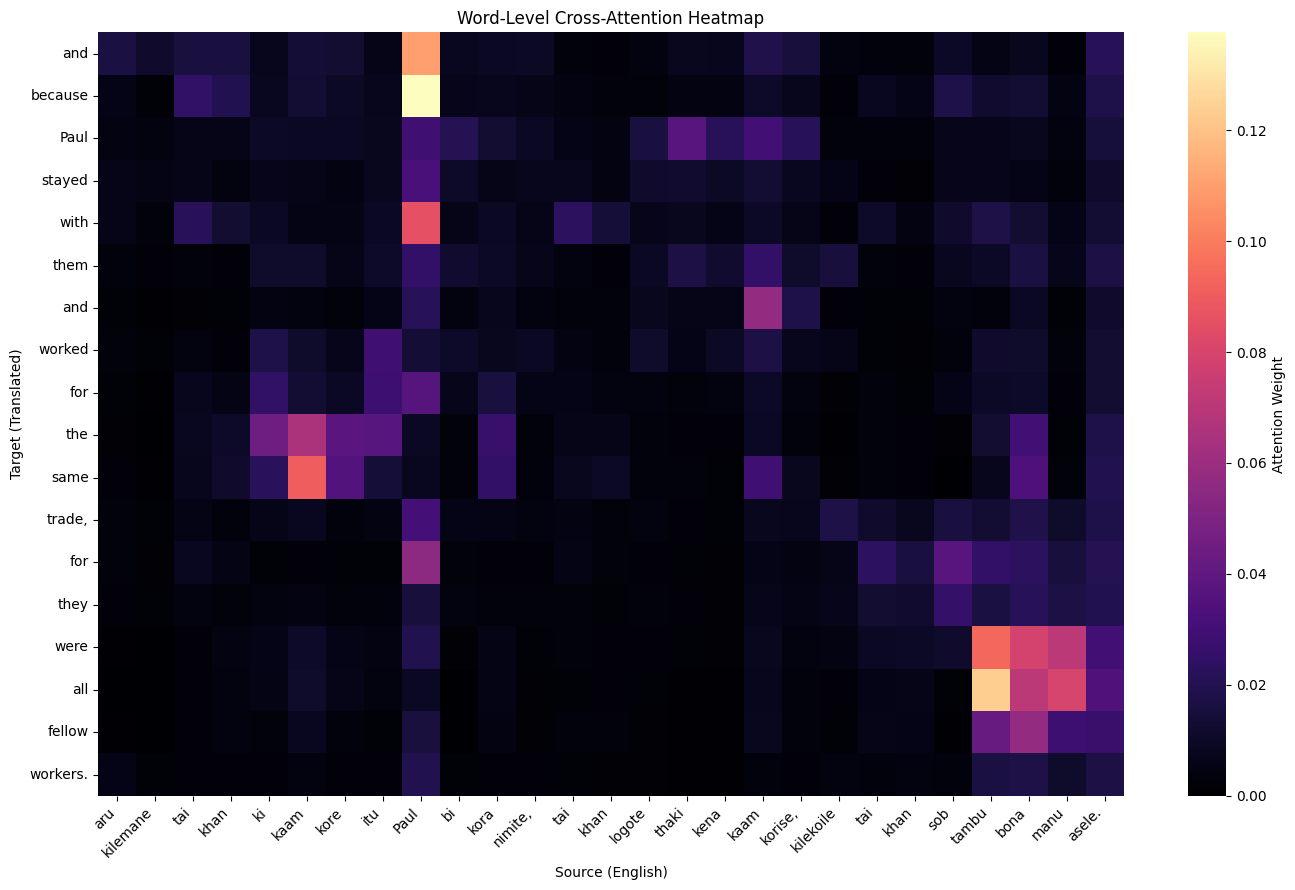


🔗 Word Alignments:

Target Word               →  Source Word
---------------------------------------------
and                       →  Paul
because                   →  Paul
Paul                      →  thaki
stayed                    →  Paul
with                      →  Paul
them                      →  Paul
and                       →  kaam
worked                    →  itu
for                       →  Paul
the                       →  kaam
same                      →  kaam
trade,                    →  Paul
for                       →  Paul
they                      →  sob
were                      →  tambu
all                       →  tambu
fellow                    →  bona
workers.                  →  Paul


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np

def merge_sentencepiece_tokens(tokens):
    words = []
    current_word = ""
    mapping = []
    word_idx = -1

    for i, tok in enumerate(tokens):
        if tok.startswith("▁") or tok.startswith("_"):  # SentencePiece or underscore-prefix
            if current_word:
                words.append(current_word)
            current_word = tok[1:]  # remove prefix
            word_idx += 1
        else:
            current_word += tok
        mapping.append(word_idx)
    if current_word:
        words.append(current_word)
    return words, mapping

def aggregate_attention(attn_matrix, src_map, tgt_map):
    num_tgt_words = max(tgt_map) + 1
    num_src_words = max(src_map) + 1
    agg_matrix = np.zeros((num_tgt_words, num_src_words))
    count_matrix = np.zeros((num_tgt_words, num_src_words))

    for i_tgt, tgt_word_idx in enumerate(tgt_map):
        for i_src, src_word_idx in enumerate(src_map):
            agg_matrix[tgt_word_idx][src_word_idx] += attn_matrix[i_tgt][i_src]
            count_matrix[tgt_word_idx][src_word_idx] += 1

    # Avoid division by zero
    count_matrix[count_matrix == 0] = 1
    return agg_matrix / count_matrix

# ----------------------------
# Your original pipeline
# ----------------------------
n = 28
tokenizer.src_lang = "eng_Latn"
tokenizer.tgt_lang = "eng_Latn"

inputs = tokenizer(
    source_texts[n], return_tensors="pt",
    max_length=128, truncation=True
).to(device)

with torch.no_grad():
    generated = model.generate(
        **inputs,
        max_length=128
    )

translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)
print(f"Input:      {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference:  {reference_texts[n]}")

decoder_input_ids = generated[:, :-1]

with torch.no_grad():
    out = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=decoder_input_ids,
        output_attentions=True,
        return_dict=True
    )

cross_attn_avg = out.cross_attentions[-1][0].mean(dim=0)  # [tgt_len, src_len]

# ── Token filtering ───────────────────────────────────────────────
special_ids = set(tokenizer.all_special_ids)

src_token_ids = inputs["input_ids"][0].tolist()
tgt_token_ids = decoder_input_ids[0].tolist()

# Build index maps: only keep non-special tokens, track their positions
src_keep = [(i, tokenizer.convert_ids_to_tokens(tid)) 
            for i, tid in enumerate(src_token_ids) if tid not in special_ids]
tgt_keep = [(i, tokenizer.convert_ids_to_tokens(tid)) 
            for i, tid in enumerate(tgt_token_ids) if tid not in special_ids]

src_indices, src_tokens_clean = zip(*src_keep) if src_keep else ([], [])
tgt_indices, tgt_tokens_clean = zip(*tgt_keep) if tgt_keep else ([], [])

src_indices = list(src_indices)
tgt_indices = list(tgt_indices)
src_tokens_clean = list(src_tokens_clean)
tgt_tokens_clean = list(tgt_tokens_clean)

# ── Slice attention to only non-special token positions ───────────
attn_np = cross_attn_avg.cpu().numpy()
attn_filtered = attn_np[np.ix_(tgt_indices, src_indices)]  # shape: [n_tgt_tokens, n_src_tokens]

# ── Merge subword tokens → words ──────────────────────────────────
src_words, src_map = merge_sentencepiece_tokens(src_tokens_clean)
tgt_words, tgt_map = merge_sentencepiece_tokens(tgt_tokens_clean)

word_attn = aggregate_attention(attn_filtered, src_map, tgt_map)

# ── Font fix for non-Latin scripts ────────────────────────────────
import matplotlib.font_manager as fm
# Use a font that supports Indic scripts if available, else fall back
try:
    import urllib.request
    urllib.request.urlretrieve(
        "https://github.com/googlefonts/noto-fonts/raw/main/hinted/ttf/NotoSans/NotoSans-Regular.ttf",
        "/tmp/NotoSans-Regular.ttf"
    )
    prop = fm.FontProperties(fname="/tmp/NotoSans-Regular.ttf")
    font_name = prop.get_name()
    plt.rcParams["font.family"] = font_name
except Exception:
    pass  # silently skip if download fails

# ── Plot ──────────────────────────────────────────────────────────
plt.figure(figsize=(14, 9))
sns.heatmap(word_attn,
            xticklabels=src_words,
            yticklabels=tgt_words,
            cmap="magma",
            vmin=0, vmax=word_attn.max(),  # auto-scale vmax
            cbar_kws={"label": "Attention Weight"})
plt.title("Word-Level Cross-Attention Heatmap")
plt.xlabel("Source (English)")
plt.ylabel("Target (Translated)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ── Alignments ────────────────────────────────────────────────────
print("\n🔗 Word Alignments:\n")
print(f"{'Target Word':<25} →  Source Word")
print("-" * 45)
for tgt_idx, tgt_word in enumerate(tgt_words):
    if tgt_idx >= word_attn.shape[0]:
        break

    if word_attn.shape[1] == 0 or len(src_words) == 0:
        continue

    src_idx = int(np.argmax(word_attn[tgt_idx]))

    if src_idx < len(src_words):
        print(f"{tgt_word:<25} →  {src_words[src_idx]}")